# Noise channel by channel

The device noise model combines several channels: gate depolarisation, T1/T2 relaxation during gates, idle relaxation
while qubits wait in the schedule, readout error, coherent error and crosstalk. Each one can be switched off, which makes it
possible to see what each contributes.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': '02f7e5c0c4f6:7:0b2c9c',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. The per-gate noise report

Every noisy response explains the channel applied to each native gate, solved so that the gate reproduces its published fidelity.

In [2]:
r = run("iqm_emerald", ghz(3), shots=1000, noise=True)
n = r["result"]["noise"]
print("calibration:", n["calibration"], "| estimated success:", round(n["estimated_success_probability"], 4))
pd.DataFrame(n["per_gate"]).T

calibration: IQM Emerald - nominal medians | estimated success: 0.9004


,count,fidelity,depolarizing_p,budget_limited,coherent,leakage
cz,2,0.995,0.002248,False,False,0.0
prx,5,0.9993,0.0,True,False,0.0


## 2. One channel at a time

GHZ₅ on Emerald with all channels, with none, and with one channel at a time. Idle windows use the qubits' own T1 and T2, so `idle` acts only together with `relaxation`: the row 'relaxation + idle' adds the waiting time to the relaxation during gates.

In [3]:
CHANNELS = ["depolarizing", "relaxation", "idle", "readout"]
def only(*keep):
    return {"model": "device", **{c: (c in keep) for c in CHANNELS}}
target = ["00000", "11111"]
rows = [{"channels": "all", "GHZ5 success": success(run("iqm_emerald", ghz(5), shots=50000, noise=True), target)},
        {"channels": "none", "GHZ5 success": success(run("iqm_emerald", ghz(5), shots=50000, noise=only()), target)}]
rows += [{"channels": name, "GHZ5 success": success(run("iqm_emerald", ghz(5), shots=50000, noise=only(*keep)), target)}
         for name, keep in [("depolarizing", ["depolarizing"]), ("relaxation during gates", ["relaxation"]),
                            ("relaxation + idle", ["relaxation", "idle"]), ("readout", ["readout"])]]
pd.DataFrame(rows).set_index("channels").round(4)

,GHZ5 success
channels,
all,0.8261
none,1.0000
depolarizing,0.9761
relaxation during gates,0.9838
relaxation + idle,0.9608
readout,0.8643


## 3. Error budget on every twin

The loss of GHZ₆ success attributable to each channel, on each twin. The idle share is the extra loss when idle windows are added to the relaxation during gates.

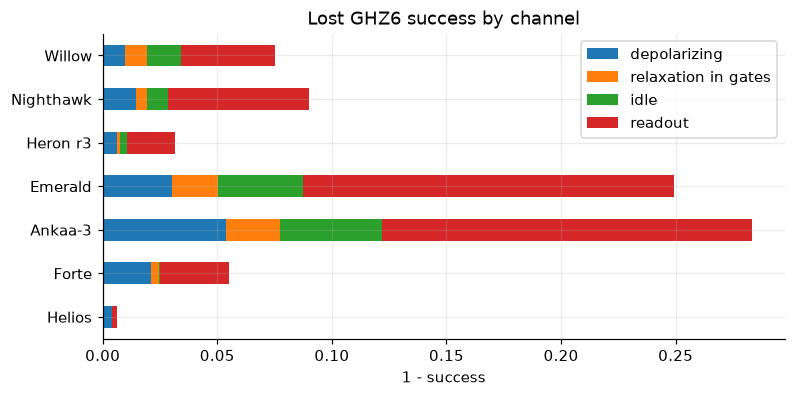

,depolarizing,relaxation in gates,idle,readout
Helios,0.0042,0.0000,0.0000,0.0021
Forte,0.0210,0.0036,0.0005,0.0301
Ankaa-3,0.0539,0.0237,0.0442,0.1617
Emerald,0.0303,0.0199,0.0373,0.1617
Heron r3,0.0061,0.0016,0.0031,0.0206
Nighthawk,0.0146,0.0047,0.0094,0.0612
Willow,0.0097,0.0097,0.0149,0.0410


In [4]:
CHANNELS = ["depolarizing", "relaxation", "idle", "readout"]
target = ["0" * 6, "1" * 6]
def loss(b, *keep):
    return 1 - success(run(b, ghz(6), shots=50000, routing=True,
                           noise={"model": "device", **{k: k in keep for k in CHANNELS}}), target)
budget = {}
for b in ALL_BACKENDS:
    gates_relax = loss(b, "relaxation")
    budget[NAMES[b]] = {"depolarizing": loss(b, "depolarizing"), "relaxation in gates": gates_relax,
                        "idle": loss(b, "relaxation", "idle") - gates_relax, "readout": loss(b, "readout")}
frame = pd.DataFrame(budget).T
frame.plot.barh(stacked=True, figsize=(8, 3.6), title="Lost GHZ6 success by channel")
plt.xlabel("1 - success"); plt.show()
frame.round(4)

## 4. Idle decoherence

While one qubit is busy, the others wait and relax. A Bell pair on two qubits waits while a third qubit runs 40 separate X pulses (kept apart by barriers), and loses fidelity when idle noise is on. The final measurements are aligned at the end, as on the device.

In [5]:
busy = program(3, ["h q[0]", "cx q[0],q[1]", *(["x q[2]", "barrier q[2]"] * 40)])
rows = []
for b in ["iqm_emerald", "ibm_heron", "google_willow"]:
    for idle in (True, False):
        r = run(b, busy, shots=50000, routing=True, noise={"model": "device", "idle": idle})
        p = sum(v for k, v in r["result"]["counts"].items() if k[-2:] in ("00", "11")) / 50000
        rows.append({"twin": NAMES[b], "idle noise": idle, "Bell success": round(p, 4)})
pd.DataFrame(rows).pivot(index="twin", columns="idle noise", values="Bell success")

idle noise,False,True
twin,,
Emerald,0.9400,0.9196
Heron r3,0.9957,0.9914
Willow,0.9862,0.9696


## 5. Estimated against executed success

The estimated success probability multiplies gate and readout fidelities. It ignores idle decoherence, so on the superconducting twins it is optimistic.

In [6]:
rows = []
for b in ALL_BACKENDS:
    r = run(b, ghz(8), shots=50000, noise=True, routing=True)
    rows.append({"twin": NAMES[b], "estimated": r["result"]["noise"]["estimated_success_probability"],
                 "executed": success(r, ["0" * 8, "1" * 8])})
t = pd.DataFrame(rows).set_index("twin")
t["estimate - executed"] = t["estimated"] - t["executed"]
t.round(4)

,estimated,executed,estimate - executed
twin,,,
Helios,0.9915,0.9913,0.0002
Forte,0.9315,0.9334,-0.0019
Ankaa-3,0.7196,0.6628,0.0568
Emerald,0.7488,0.6980,0.0508
Heron r3,0.9645,0.9600,0.0045
Nighthawk,0.8941,0.8885,0.0056
Willow,0.9323,0.9110,0.0213


## Takeaways

- Every channel can be switched off, which turns the noise model into an error budget.
- Idle decoherence is invisible to a product-of-fidelities estimate but matters on the superconducting twins.